# A3TGCN

Train the main model with different input parameters and different adjacency types

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
from tqdm import tqdm
import pickle
import random
import os
from scipy import stats

from sklearn.preprocessing import StandardScaler
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
# from torch_geometric_temporal.nn.recurrent import A3TGCN
# from torch_geometric_temporal.signal import temporal_signal_split
from torch_geometric.data import Data

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

import os
import pickle
import torch
import numpy as np
import pandas as pd

In [2]:
from util import * 

## Load the time series data

In [3]:
skip_dates = skip_dates = ['2021-08-31', '2021-11-05']# needs to be filled
start_date_pre = '2020-05-01'
end_date_pre = '2022-02-18'

rolling_window = 28

start_date = pd.to_datetime(start_date_pre)  + pd.Timedelta(days=rolling_window-1)
end_date = pd.to_datetime(end_date_pre)      # + pd.Timedelta(days=rolling_window-1)
print(start_date, end_date)

num_timesteps_in = 14
num_timesteps_out = 3


2020-05-28 00:00:00 2022-02-18 00:00:00


In [4]:
#
# Normalize
# 

# Filter conditions: 
# - mainland counties
# - population >= 100k

import geopandas as gpd
counties = gpd.read_file(r'county_data.shp') 

import json
with open('county_fips_mainland.txt', 'r') as file:
    mainland_countyfips = json.load(file)
    
tweets_baseline = pd.read_csv(r"tweets_keywords_covid_baseline_topic.csv", index_col=0)
# \data\tweets_time_series\tweets_keywords_covid_baseline_topic.csv"
cases = pd.read_csv(r"daily_new_cases.csv", index_col=0)

counties = counties[counties['countyfips'].isin([int(el) for el in mainland_countyfips])]
len(counties)

best_counties = counties[counties['countyfips'].isin(counties[counties['population'] > 99999]['countyfips'])]


In [5]:
#
#Create preprocessed data
#

# create cases data
# Preprocess cases time series data and return multiple processed datasets
(
    cases_28,
    cases_log,
    cases_difference,
    cases_filtered_butterworth,
    cases_filtered_butterworth_log,
    cases_filtered_butterworth_log_lagged,
    cases_standardized,
    cases_ema,
    cases_hp_filtered,
    cases_hp_filtered_log,
    cases_merged_state_mean
) = prepro_time_series_data(cases,
                            counties,
                            best_counties,
                            start_date_pre,
                            end_date_pre,
                            skip_dates,
                            rolling_window
                        )

# create tweets data; +prepro tweets_baseline data
tweets_baseline = tweets_baseline.loc[start_date_pre:end_date_pre]
tweets_baseline = tweets_baseline.fillna(0)
tweets_baseline_filtered = tweets_baseline.drop(columns='0')
# Preprocess tweets time series data and return multiple processed datasets
(
    tweets_28,
    tweets_log,
    tweets_difference,
    tweets_filtered_butterworth,
    tweets_filtered_butterworth_log,
    tweets_filtered_butterworth_log_lagged,
    tweets_standardized,
    tweets_ema,
    tweets_hp_filtered,
    tweets_hp_filtered_log,
    tweets_merged_state_mean
) = prepro_time_series_data(tweets_baseline_filtered,
                            counties,
                            best_counties,
                            start_date_pre,
                            end_date_pre,
                            skip_dates,
                            rolling_window
                        )


# create dfs lists
train_valid_dfs = [cases_filtered_butterworth, tweets_filtered_butterworth]

print('train_valid_dfs[0].shape', train_valid_dfs[0].shape)


train_valid_dfs[0].shape (630, 594)


# Plot time series

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
def plot_timeseries(df1, df2):
    # Prepare your data
    df1 = df1.copy()
    df2 = df2.copy()
    df1.index = pd.to_datetime(df1.index)
    df2.index = pd.to_datetime(df2.index)

    # Make sure both dataframes have the same subset of counties (columns)
    shared_columns = df1.columns.intersection(df2.columns)
    df1 = df1[shared_columns]
    df2 = df2[shared_columns]

    # Create a consistent color map
    cmap = plt.get_cmap('tab20')  # You can also use 'tab10', 'Set1', etc.
    colors = cmap(np.linspace(0, 1, len(shared_columns)))
    color_dict = {col: colors[i] for i, col in enumerate(shared_columns)}

    # Plot for df1 (e.g. cases)
    plt.figure(figsize=(14, 7))
    for county in shared_columns:
        plt.plot(df1.index, df1[county], label=str(county), color=color_dict[county], alpha=0.8)

    plt.title('Population-Normalized Cases Time Series', fontsize=16)
    plt.xlabel('Date', fontsize=14)
    plt.ylabel('Value', fontsize=14)
    # plt.legend(loc='upper left')
    plt.xticks(rotation=45)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Plot for df2 (e.g. tweets)
    plt.figure(figsize=(14, 7))
    for county in shared_columns:
        plt.plot(df2.index, df2[county], label=str(county), color=color_dict[county], alpha=0.8)

    plt.title('Population-Normalized Tweets Time Series', fontsize=16)
    plt.xlabel('Date', fontsize=14)
    plt.ylabel('Value', fontsize=14)
    # plt.legend(loc='upper left')
    plt.xticks(rotation=45)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

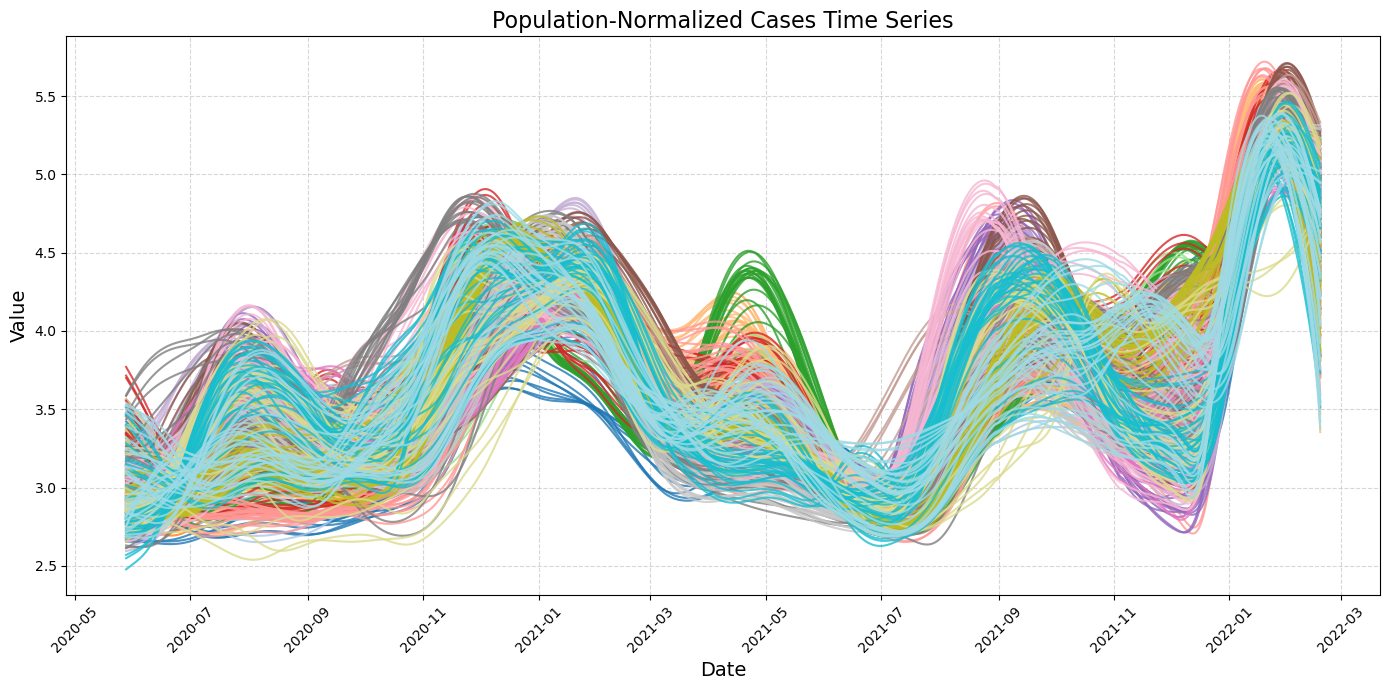

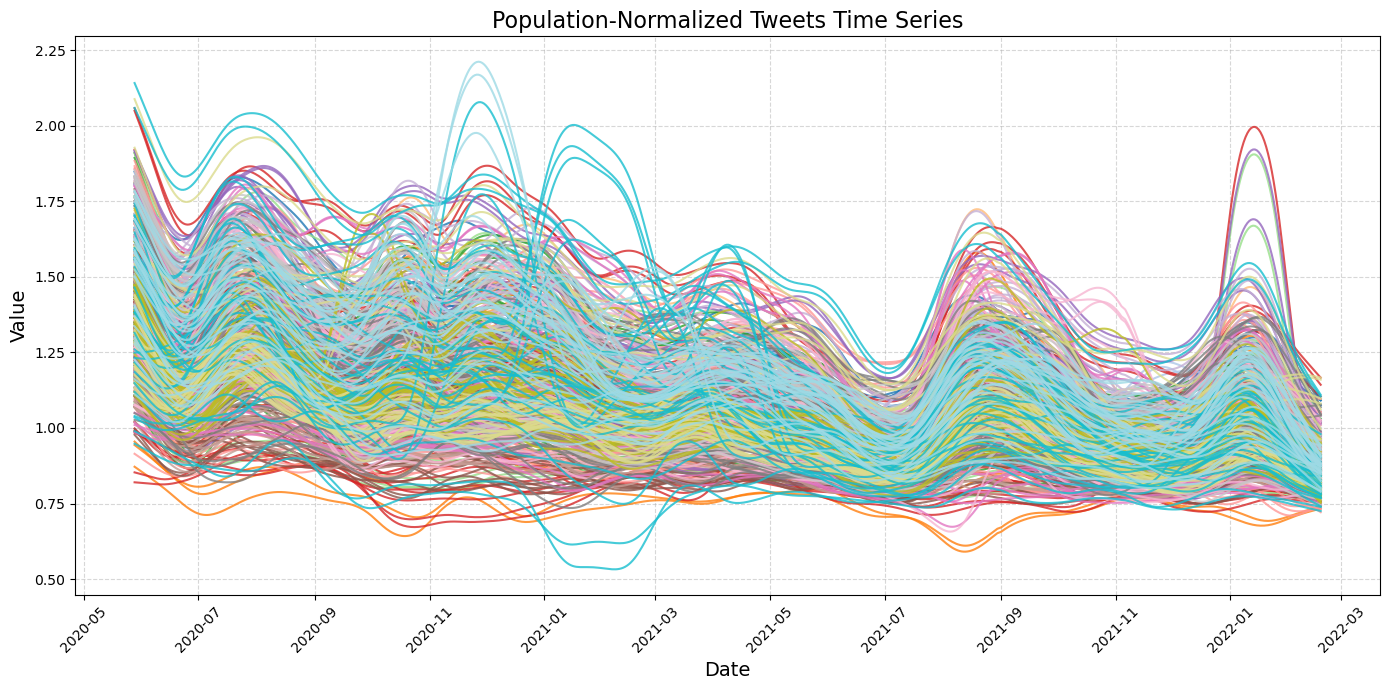

In [7]:
df1 = cases_filtered_butterworth_log#[[41005]]
df2 = tweets_filtered_butterworth_log #[[41005]]#just to choose one county
plot_timeseries(df1, df2)

## Building the model

In [8]:
# TGCN

import torch
from torch_geometric.nn import GCNConv


class TGCN(torch.nn.Module):
    r"""An implementation of the Temporal Graph Convolutional Gated Recurrent Cell.
    For details see this paper: `"T-GCN: A Temporal Graph ConvolutionalNetwork for
    Traffic Prediction." <https://arxiv.org/abs/1811.05320>`_

    Args:
        in_channels (int): Number of input features.
        out_channels (int): Number of output features.
        improved (bool): Stronger self loops. Default is False.
        cached (bool): Caching the message weights. Default is False.
        add_self_loops (bool): Adding self-loops for smoothing. Default is True.
    """

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        improved: bool = False,
        cached: bool = False,
        add_self_loops: bool = True,
    ):
        super(TGCN, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.improved = improved
        self.cached = cached
        self.add_self_loops = add_self_loops

        self._create_parameters_and_layers()

    def _create_update_gate_parameters_and_layers(self):

        self.conv_z = GCNConv(
            in_channels=self.in_channels,
            out_channels=self.out_channels,
            improved=self.improved,
            cached=self.cached,
            add_self_loops=self.add_self_loops,
        )

        self.linear_z = torch.nn.Linear(2 * self.out_channels, self.out_channels)

    def _create_reset_gate_parameters_and_layers(self):

        self.conv_r = GCNConv(
            in_channels=self.in_channels,
            out_channels=self.out_channels,
            improved=self.improved,
            cached=self.cached,
            add_self_loops=self.add_self_loops,
        )

        self.linear_r = torch.nn.Linear(2 * self.out_channels, self.out_channels)

    def _create_candidate_state_parameters_and_layers(self):

        self.conv_h = GCNConv(
            in_channels=self.in_channels,
            out_channels=self.out_channels,
            improved=self.improved,
            cached=self.cached,
            add_self_loops=self.add_self_loops,
        )

        self.linear_h = torch.nn.Linear(2 * self.out_channels, self.out_channels)

    def _create_parameters_and_layers(self):
        self._create_update_gate_parameters_and_layers()
        self._create_reset_gate_parameters_and_layers()
        self._create_candidate_state_parameters_and_layers()

    def _set_hidden_state(self, X, H):
        if H is None:
            H = torch.zeros(X.shape[0], self.out_channels).to(X.device)
        return H

    def _calculate_update_gate(self, X, edge_index, edge_weight, H):
        Z = torch.cat([self.conv_z(X, edge_index, edge_weight), H], axis=1)
        Z = self.linear_z(Z)
        Z = torch.sigmoid(Z)
        return Z

    def _calculate_reset_gate(self, X, edge_index, edge_weight, H):
        R = torch.cat([self.conv_r(X, edge_index, edge_weight), H], axis=1)
        R = self.linear_r(R)
        R = torch.sigmoid(R)
        return R

    def _calculate_candidate_state(self, X, edge_index, edge_weight, H, R):
        H_tilde = torch.cat([self.conv_h(X, edge_index, edge_weight), H * R], axis=1)
        H_tilde = self.linear_h(H_tilde)
        H_tilde = torch.tanh(H_tilde)
        return H_tilde

    def _calculate_hidden_state(self, Z, H, H_tilde):
        H = Z * H + (1 - Z) * H_tilde
        return H

    def forward(
        self,
        X: torch.FloatTensor,
        edge_index: torch.LongTensor,
        edge_weight: torch.FloatTensor = None,
        H: torch.FloatTensor = None,
    ) -> torch.FloatTensor:
        """
        Making a forward pass. If edge weights are not present the forward pass
        defaults to an unweighted graph. If the hidden state matrix is not present
        when the forward pass is called it is initialized with zeros.

        Arg types:
            * **X** *(PyTorch Float Tensor)* - Node features.
            * **edge_index** *(PyTorch Long Tensor)* - Graph edge indices.
            * **edge_weight** *(PyTorch Long Tensor, optional)* - Edge weight vector.
            * **H** *(PyTorch Float Tensor, optional)* - Hidden state matrix for all nodes.

        Return types:
            * **H** *(PyTorch Float Tensor)* - Hidden state matrix for all nodes.
        """
        H = self._set_hidden_state(X, H)
        Z = self._calculate_update_gate(X, edge_index, edge_weight, H)
        R = self._calculate_reset_gate(X, edge_index, edge_weight, H)
        H_tilde = self._calculate_candidate_state(X, edge_index, edge_weight, H, R)
        H = self._calculate_hidden_state(Z, H, H_tilde)
        return H


In [9]:
# A3TGCN

import torch
from torch_geometric.nn import GCNConv


class A3TGCN(torch.nn.Module):
    r"""An implementation of the Attention Temporal Graph Convolutional Cell.
    For details see this paper: `"A3T-GCN: Attention Temporal Graph Convolutional
    Network for Traffic Forecasting." <https://arxiv.org/abs/2006.11583>`_

    Args:
        in_channels (int): Number of input features.
        out_channels (int): Number of output features.
        periods (int): Number of time periods.
        improved (bool): Stronger self loops (default :obj:`False`).
        cached (bool): Caching the message weights (default :obj:`False`).
        add_self_loops (bool): Adding self-loops for smoothing (default :obj:`True`).
    """

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        periods: int,
        improved: bool = False,
        cached: bool = False,
        add_self_loops: bool = True
    ):
        super(A3TGCN, self).__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.periods = periods
        self.improved = improved
        self.cached = cached
        self.add_self_loops = add_self_loops
        self._setup_layers()

    def _setup_layers(self):
        self._base_tgcn = TGCN(
            in_channels=self.in_channels,
            out_channels=self.out_channels,
            improved=self.improved,
            cached=self.cached,
            add_self_loops=self.add_self_loops,
        )
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self._attention = torch.nn.Parameter(torch.empty(self.periods, device=device))
        torch.nn.init.uniform_(self._attention)

    def forward(
        self,
        X: torch.FloatTensor,
        edge_index: torch.LongTensor,
        edge_weight: torch.FloatTensor = None,
        H: torch.FloatTensor = None,
    ) -> torch.FloatTensor:
        """
        Making a forward pass. If edge weights are not present the forward pass
        defaults to an unweighted graph. If the hidden state matrix is not present
        when the forward pass is called it is initialized with zeros.

        Arg types:
            * **X** (PyTorch Float Tensor): Node features for T time periods.
            * **edge_index** (PyTorch Long Tensor): Graph edge indices.
            * **edge_weight** (PyTorch Long Tensor, optional)*: Edge weight vector.
            * **H** (PyTorch Float Tensor, optional): Hidden state matrix for all nodes.

        Return types:
            * **H** (PyTorch Float Tensor): Hidden state matrix for all nodes.
        """
        H_accum = 0
        probs = torch.nn.functional.softmax(self._attention, dim=0)
        for period in range(self.periods):
            H_accum = H_accum + probs[period] * self._base_tgcn(
                X[:, :, period], edge_index, edge_weight, H
            )
        return H_accum

In [10]:
# Build basic gnn
# 

import torch
import torch.nn as nn
import torch.nn.functional as F


class TemporalGNN(torch.nn.Module):
    def __init__(self, node_features, periods):
        super(TemporalGNN, self).__init__()
        # Attention Temporal Graph Convolutional Cell
        self.tgnn = A3TGCN(in_channels=node_features, 
                           out_channels=32, 
                           periods=periods)
        # Equals single-shot prediction
        self.linear = torch.nn.Linear(32, periods)

    def forward(self, x, edge_index):
        """
        x = Node features for T time steps
        edge_index = Graph edge indices
        """
        
        h = self.tgnn(x, edge_index)
        h = F.relu(h)
        h = self.linear(h)
        return h





In [11]:
# # test model build to investigate model characteristics

# model = TemporalGNN(node_features=len(train_valid_dfs), periods=num_timesteps_out).to('cuda')
# print(model)

In [12]:
# params = [(name, p.numel()) for name, p in model.named_parameters() if p.requires_grad]
# params_sorted = sorted(params, key=lambda x: x[1], reverse=True)

# for name, count in params_sorted:
#     print(f"{name}: {count}")

# total_params = sum(count for _, count in params_sorted)
# print(f"Total learnable parameters: {total_params}")

# Cross Validation & Eval

In [13]:
# import torch

# # Force CPU only
# device = torch.device("cpu")

# print("Using device:", device)

In [14]:
# Empty the CUDA cache if available and set device accordingly
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    device = torch.device("cuda")
    print("CUDA available")
else:
    device = torch.device("cpu")
    print("CUDA not available, using CPU")

CUDA available


In [15]:
#
# set seeds for weight init
#

set_seed(42)

In [16]:
# StaticGraphTemporalSignal
%config Completer.use_jedi = False
from typing import Sequence, Union

Edge_Index = Union[np.ndarray, None]
Edge_Weight = Union[np.ndarray, None]
Node_Features = Sequence[Union[np.ndarray, None]]
Targets = Sequence[Union[np.ndarray, None]]
Additional_Features = Sequence[np.ndarray]

class StaticGraphTemporalSignal(object):
    r"""A data iterator object to contain a static graph with a dynamically
    changing constant time difference temporal feature set (multiple signals).
    The node labels (target) are also temporal. The iterator returns a single
    constant time difference temporal snapshot for a time period (e.g. day or week).
    This single temporal snapshot is a Pytorch Geometric Data object. Between two
    temporal snapshots the features and optionally passed attributes might change.
    However, the underlying graph is the same.

    Args:
        edge_index (Numpy array): Index tensor of edges.
        edge_weight (Numpy array): Edge weight tensor.
        features (Sequence of Numpy arrays): Sequence of node feature tensors.
        targets (Sequence of Numpy arrays): Sequence of node label (target) tensors.
        **kwargs (optional Sequence of Numpy arrays): Sequence of additional attributes.
    """

    def __init__(
        self,
        edge_index: Edge_Index,
        edge_weight: Edge_Weight,
        features: Node_Features,
        targets: Targets,
        **kwargs: Additional_Features
    ):
        self.edge_index = edge_index
        self.edge_weight = edge_weight
        self.features = features
        self.targets = targets
        self.additional_feature_keys = []
        for key, value in kwargs.items():
            setattr(self, key, value)
            self.additional_feature_keys.append(key)
        self._check_temporal_consistency()
        self._set_snapshot_count()

    def _check_temporal_consistency(self):
        assert len(self.features) == len(
            self.targets
        ), "Temporal dimension inconsistency."
        for key in self.additional_feature_keys:
            assert len(self.targets) == len(
                getattr(self, key)
            ), "Temporal dimension inconsistency."

    def _set_snapshot_count(self):
        self.snapshot_count = len(self.features)

        # This function was added by me so that this dataset can be used with the split_train_test function from scikit learn
    def __len__(self): 
        return self.snapshot_count

    def _get_edge_index(self):
        if self.edge_index is None:
            return self.edge_index
        else:
            return torch.LongTensor(self.edge_index)

    def _get_edge_weight(self):
        if self.edge_weight is None:
            return self.edge_weight
        else:
            return torch.FloatTensor(self.edge_weight)

    def _get_features(self, time_index: int):
        if self.features[time_index] is None:
            return self.features[time_index]
        else:
            return torch.FloatTensor(self.features[time_index])

    def _get_target(self, time_index: int):
        if self.targets[time_index] is None:
            return self.targets[time_index]
        else:
            if self.targets[time_index].dtype.kind == "i":
                return torch.LongTensor(self.targets[time_index])
            elif self.targets[time_index].dtype.kind == "f":
                return torch.FloatTensor(self.targets[time_index])

    def _get_additional_feature(self, time_index: int, feature_key: str):
        feature = getattr(self, feature_key)[time_index]
        if feature.dtype.kind == "i":
            return torch.LongTensor(feature)
        elif feature.dtype.kind == "f":
            return torch.FloatTensor(feature)

    def _get_additional_features(self, time_index: int):
        additional_features = {
            key: self._get_additional_feature(time_index, key)
            for key in self.additional_feature_keys
        }
        return additional_features

    def __getitem__(self, time_index: Union[int, slice]):
        if isinstance(time_index, slice):
            snapshot = StaticGraphTemporalSignal(
                self.edge_index,
                self.edge_weight,
                self.features[time_index],
                self.targets[time_index],
                **{key: getattr(self, key)[time_index] for key in self.additional_feature_keys}
            )
        else:
            x = self._get_features(time_index)
            edge_index = self._get_edge_index()
            edge_weight = self._get_edge_weight()
            y = self._get_target(time_index)
            additional_features = self._get_additional_features(time_index)

            snapshot = Data(x=x, edge_index=edge_index, edge_attr=edge_weight,
                            y=y, **additional_features)
        return snapshot

    def __next__(self):
        if self.t < len(self.features):
            snapshot = self[self.t]
            self.t = self.t + 1
            return snapshot
        else:
            self.t = 0
            raise StopIteration

    def __iter__(self):
        self.t = 0
        return self

# DynamicGraphTemporalSignal

import torch
import numpy as np
from typing import Sequence, Union
from torch_geometric.data import Data


Edge_Indices = Sequence[Union[np.ndarray, None]]
Edge_Weights = Sequence[Union[np.ndarray, None]]
Node_Features = Sequence[Union[np.ndarray, None]]
Targets = Sequence[Union[np.ndarray, None]]
Additional_Features = Sequence[np.ndarray]


class DynamicGraphTemporalSignal(object):
    r"""A data iterator object to contain a dynamic graph with a
    changing edge set and weights . The feature set and node labels
    (target) are also dynamic. The iterator returns a single discrete temporal
    snapshot for a time period (e.g. day or week). This single snapshot is a
    Pytorch Geometric Data object. Between two temporal snapshots the edges,
    edge weights, target matrices and optionally passed attributes might change.

    Args:
        edge_indices (Sequence of Numpy arrays): Sequence of edge index tensors.
        edge_weights (Sequence of Numpy arrays): Sequence of edge weight tensors.
        features (Sequence of Numpy arrays): Sequence of node feature tensors.
        targets (Sequence of Numpy arrays): Sequence of node label (target) tensors.
        **kwargs (optional Sequence of Numpy arrays): Sequence of additional attributes.
    """

    def __init__(
        self,
        edge_indices: Edge_Indices,
        edge_weights: Edge_Weights,
        features: Node_Features,
        targets: Targets,
        **kwargs: Additional_Features
    ):
        self.edge_indices = edge_indices
        self.edge_weights = edge_weights
        self.features = features
        self.targets = targets
        self.additional_feature_keys = []
        for key, value in kwargs.items():
            setattr(self, key, value)
            self.additional_feature_keys.append(key)
        self._check_temporal_consistency()
        self._set_snapshot_count()
        
    # This function was added by me so that this dataset can be used with the split_train_test function from scikit learn
    def __len__(self): 
        return self.snapshot_count

    def _check_temporal_consistency(self):
        assert len(self.features) == len(
            self.targets
        ), "Temporal dimension inconsistency."
        assert len(self.edge_indices) == len(
            self.edge_weights
        ), "Temporal dimension inconsistency."
        assert len(self.features) == len(
            self.edge_weights
        ), "Temporal dimension inconsistency."
        for key in self.additional_feature_keys:
            assert len(self.targets) == len(
                getattr(self, key)
            ), "Temporal dimension inconsistency."

    def _set_snapshot_count(self):
        self.snapshot_count = len(self.features)

    def _get_edge_index(self, time_index: int):
        if self.edge_indices[time_index] is None:
            return self.edge_indices[time_index]
        else:
            return torch.LongTensor(self.edge_indices[time_index])

    def _get_edge_weight(self, time_index: int):
        if self.edge_weights[time_index] is None:
            return self.edge_weights[time_index]
        else:
            return torch.FloatTensor(self.edge_weights[time_index])

    def _get_features(self, time_index: int):
        if self.features[time_index] is None:
            return self.features[time_index]
        else:
            return torch.FloatTensor(self.features[time_index])

    def _get_target(self, time_index: int):
        if self.targets[time_index] is None:
            return self.targets[time_index]
        else:
            if self.targets[time_index].dtype.kind == "i":
                return torch.LongTensor(self.targets[time_index])
            elif self.targets[time_index].dtype.kind == "f":
                return torch.FloatTensor(self.targets[time_index])

    def _get_additional_feature(self, time_index: int, feature_key: str):
        feature = getattr(self, feature_key)[time_index]
        if feature.dtype.kind == "i":
            return torch.LongTensor(feature)
        elif feature.dtype.kind == "f":
            return torch.FloatTensor(feature)

    def _get_additional_features(self, time_index: int):
        additional_features = {
            key: self._get_additional_feature(time_index, key)
            for key in self.additional_feature_keys
        }
        return additional_features

    def __getitem__(self, time_index: Union[int, slice]):
        if isinstance(time_index, slice):
            snapshot = DynamicGraphTemporalSignal(
                self.edge_indices[time_index],
                self.edge_weights[time_index],
                self.features[time_index],
                self.targets[time_index],
                **{key: getattr(self, key)[time_index] for key in self.additional_feature_keys}
            )
        else:
            x = self._get_features(time_index)
            edge_index = self._get_edge_index(time_index)
            edge_weight = self._get_edge_weight(time_index)
            y = self._get_target(time_index)
            additional_features = self._get_additional_features(time_index)

            snapshot = Data(x=x, edge_index=edge_index, edge_attr=edge_weight,
                            y=y, **additional_features)
        return snapshot

    def __next__(self):
        if self.t < len(self.features):
            snapshot = self[self.t]
            self.t = self.t + 1
            return snapshot
        else:
            self.t = 0
            raise StopIteration

    def __iter__(self):
        self.t = 0
        return self


In [ ]:

MODEL_MAP = {
    # 'M1': 'casesonly_static',# 
    # # 'M2': 'casesonly_mobs', 
    # # 'M3': 'casesonly_sem',
    'M4': 'cases_tweets_static', # 
    # 'M5': 'cases_tweets_mobs', # 
    # # 'M6': 'cases_tweets_sem',
    'M7': 'cases_randts_static', #
    # # 'M8': 'cases_randts_mobs',
    # # 'M9': 'cases_randts_sem',
    'M10': 'casesonly_static_randadj', # 
    # # 'M11': 'casesonly_dynamic_randadj', 
    'M12': 'cases_tweets_static_randadj', # 
    # # 'M13': 'cases_tweets_dynamic_randadj',
}

set_seed(42)

num_epochs = 128 
num_timesteps_in = 14
num_timesteps_out = 3
num_folds = 16
random_seed = 1369 
loss_type = 'rmse'
lr_rate = 1e-4
opti = 'adamw'
loss_types = ['mae']


model_list = list(MODEL_MAP.keys())
for model_load_name in model_list: 
    # get data
    
    gnndataset, dfs = prepare_model_dataset(MODEL_MAP, model_load_name, train_valid_dfs, 
                                             start_date, end_date, best_counties, 
                                             num_timesteps_in=num_timesteps_in, num_timesteps_out=num_timesteps_out,
                                            folder= r"datasets/rescaled_adjs/")
   
    
    model_name = model_load_name + f'_{opti}_{lr_rate}_{loss_type}_zscore_RescalingOfAdjs_NewTsButterNoLog_16folds'
    print('created dataset ', model_name)

    print('Starting cross_val')
    cross_val_results = cross_val_yeojohnson_norm(model_name, #cross_val
                    dfs,
                    gnndataset,
                    TemporalGNN,
                    device,
                    lr_rate=lr_rate,
                    opti=opti,
                    num_folds=num_folds,
                    num_epochs=num_epochs,
                    train_size=0.7,
                    batch_size=1,
                    model_checkpoint_dir='model_checkpoints',
                    random_seed=random_seed,
                    num_timesteps_out=num_timesteps_out, loss_type=loss_type,
                                                scaling_method='z_score')

    # eval
    print('Starting eval')
    eval( test_models=cross_val_results, lr_rate=lr_rate, opti=opti, loss_type=loss_type, dfs=dfs, counties=counties, model_name=model_name, device_in=device)


=== Preparing Model: cases_tweets_static (in=14, out=3) ===
full_path:datasets/rescaled_adjs/dataset_M4_cases_tweets_static_in14_out3.pkl
Loaded dataset from: datasets/rescaled_adjs/dataset_M4_cases_tweets_static_in14_out3.pkl
created dataset  M4_adamw_0.0001_rmse_zscore_RescalingOfAdjs_NewTsButterNoLog_16folds
Starting cross_val


100%|██████████| 16/16 [2:08:29<00:00, 481.84s/it] 


Starting eval


100%|██████████| 16/16 [00:11<00:00,  1.45it/s]



=== Preparing Model: cases_randts_static (in=14, out=3) ===
full_path:datasets/rescaled_adjs/dataset_M7_cases_randts_static_in14_out3.pkl
Loaded dataset from: datasets/rescaled_adjs/dataset_M7_cases_randts_static_in14_out3.pkl
created dataset  M7_adamw_0.0001_rmse_zscore_RescalingOfAdjs_NewTsButterNoLog_16folds
Starting cross_val


100%|██████████| 16/16 [2:08:36<00:00, 482.28s/it] 


... (6 outputs left out)


=== Preparing Model: cases_tweets_static_randadj (in=14, out=3) ===
full_path:datasets/rescaled_adjs/dataset_M12_cases_tweets_static_randadj_in14_out3.pkl
Loaded dataset from: datasets/rescaled_adjs/dataset_M12_cases_tweets_static_randadj_in14_out3.pkl
created dataset  M12_adamw_0.0001_rmse_zscore_RescalingOfAdjs_NewTsButterNoLog_16folds
Starting cross_val


100%|██████████| 16/16 [2:08:42<00:00, 482.67s/it] 


Starting eval


100%|██████████| 16/16 [00:10<00:00,  1.46it/s]
